<a href="https://colab.research.google.com/github/Basma328/Beginning_Bioinformatics/blob/main/Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using cleaned dataset: camptothecin_cleaned_full.csv
Using training IDs: training_ids.csv
Matched training cell lines: 463
Cancer types represented: 35

Preprocessing summary
Starting gene columns: 54137
Genes removed for missing/invalid values: 0
Constant genes removed: 3653
Genes retained: 50484
Transformation: log2(RPKM + 1)
Scaling: mean 0 and standard deviation 1 per gene
Expression matrix used: (463, 50484)

PC1 variance explained: 4.98%
PC2 variance explained: 3.36%
PC1 + PC2 variance explained: 8.34%


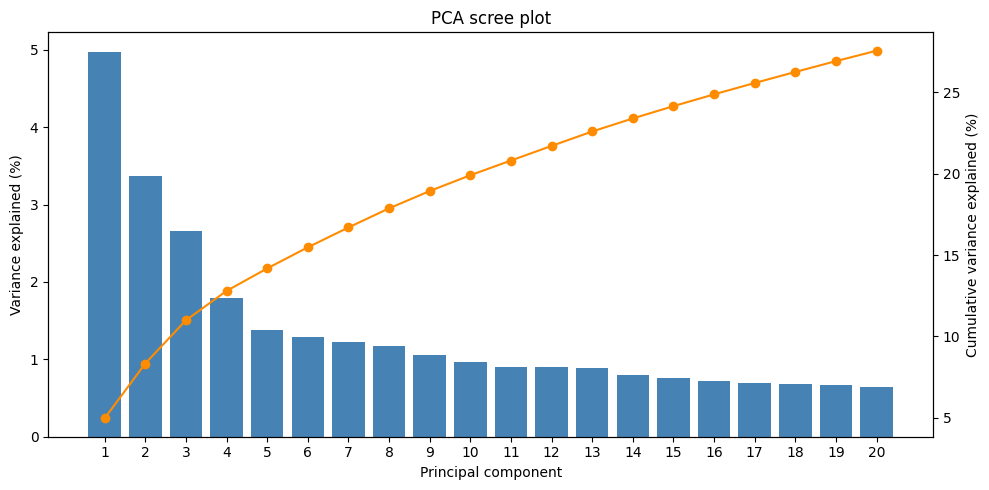

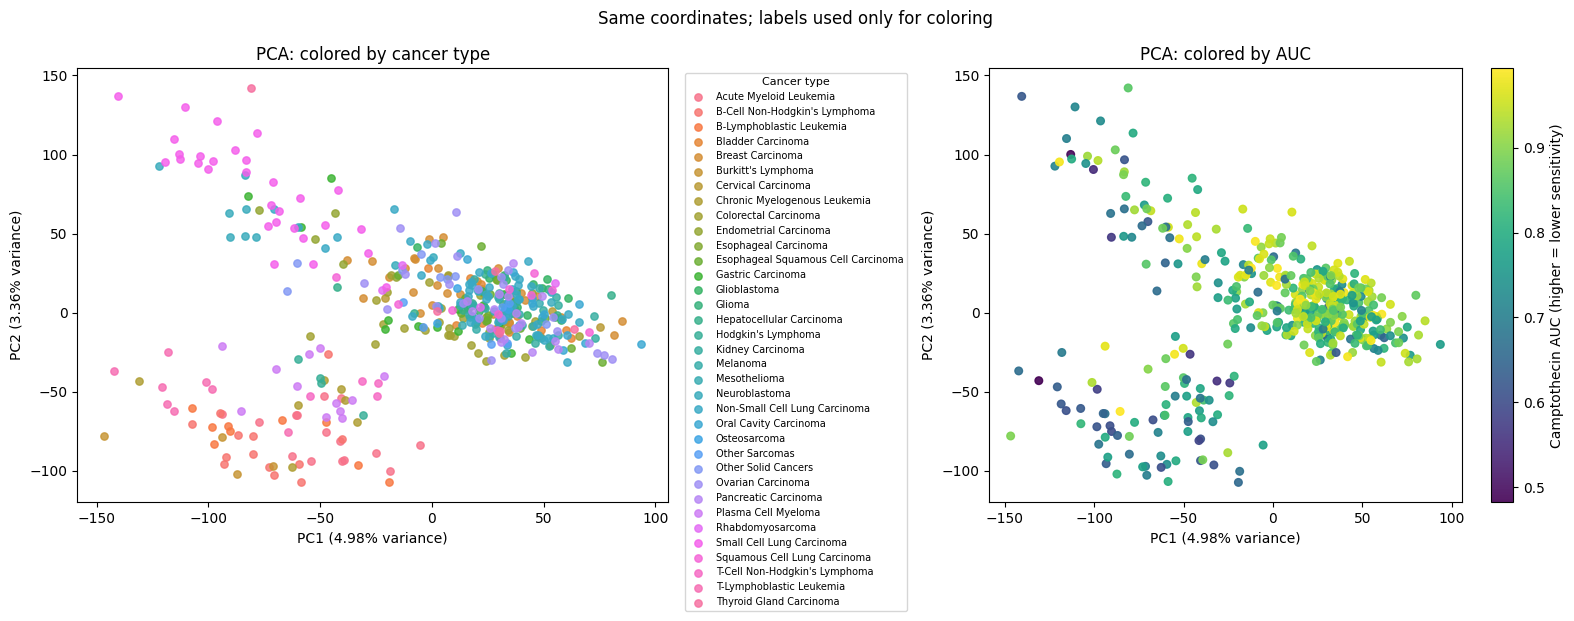


UMAP input: first 50 PCA components
UMAP settings:
n_components: 2
n_neighbors: 15
min_dist: 0.1
metric: euclidean
random_state: 42
transform_seed: 42
init: spectral
low_memory: True
n_jobs: 1


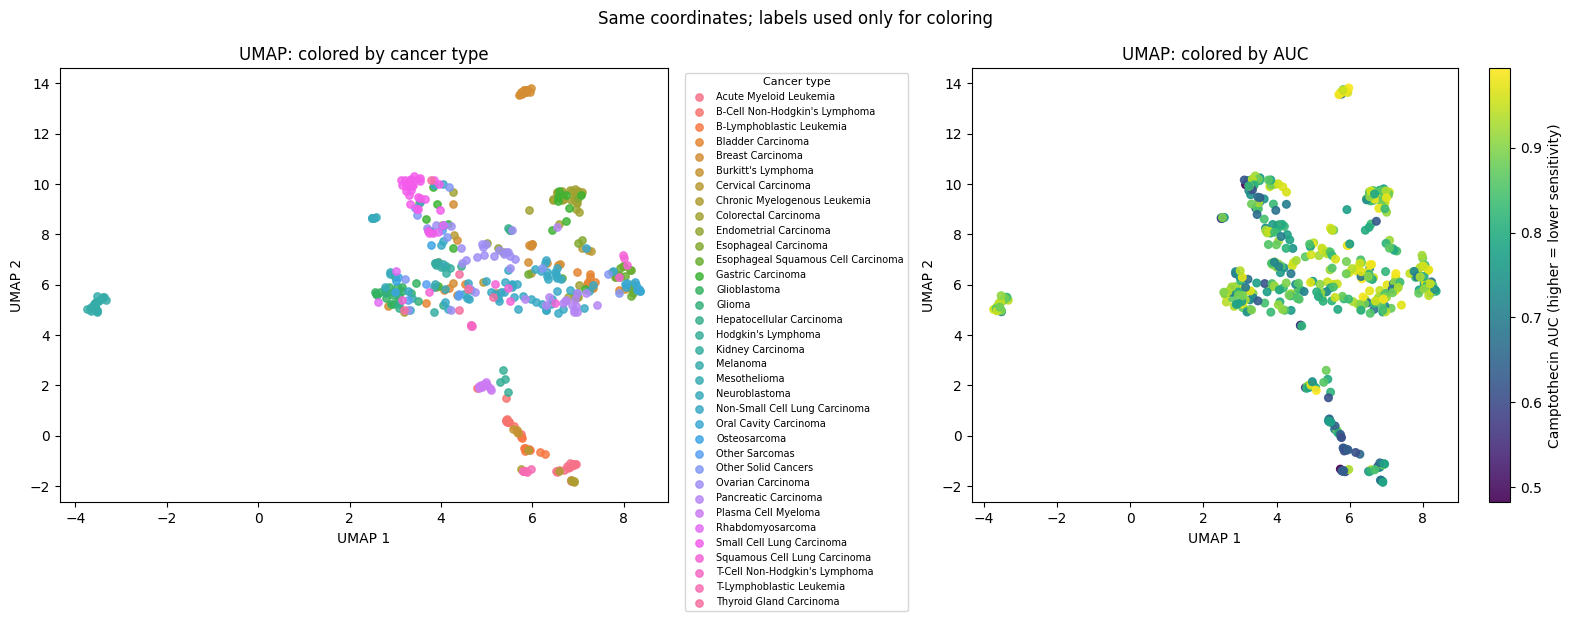


Saved: pca_umap_training_coordinates.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# Install UMAP
%pip -q install umap-learn

# Import packages
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap

from google.colab import files
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Find the files already in Colab's working folder
DATA_DIR = Path("/content")

cleaned_options = sorted(DATA_DIR.glob("camptothecin_cleaned_full.csv*"))
training_file = DATA_DIR / "training_ids.csv"

if not cleaned_options:
    raise FileNotFoundError(
        "Could not find camptothecin_cleaned_full.csv or .csv.gz in /content."
    )

if not training_file.exists():
    raise FileNotFoundError("Could not find training_ids.csv in /content.")

# If both cleaned CSV versions exist, prefer the compressed one
cleaned_file = next(
    (path for path in cleaned_options if path.name.lower().endswith(".csv.gz")),
    cleaned_options[0]
)

# Read the files
data = pd.read_csv(cleaned_file, compression="infer")
training_ids_df = pd.read_csv(training_file)

print("Using cleaned dataset:", cleaned_file.name)
print("Using training IDs:", training_file.name)

# Clean column names and sample IDs
data.columns = (
    data.columns.astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)

training_ids_df.columns = (
    training_ids_df.columns.astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)

# Check required columns
if "sampleId" not in data.columns:
    raise ValueError("The cleaned dataset needs a 'sampleId' column.")

if "sampleId" not in training_ids_df.columns:
    raise ValueError("training_ids.csv needs a 'sampleId' column.")

if not {"cancer_type", "AUC"}.issubset(data.columns):
    raise ValueError("The cleaned dataset needs 'cancer_type' and 'AUC' columns.")

# Clean and check the sample IDs
data["sampleId"] = data["sampleId"].astype("string").str.strip()
training_ids_df["sampleId"] = (
    training_ids_df["sampleId"].astype("string").str.strip()
)

if data["sampleId"].isna().any() or (data["sampleId"] == "").any():
    raise ValueError("Blank sample IDs found in the cleaned dataset.")

if training_ids_df["sampleId"].isna().any() or (
    training_ids_df["sampleId"] == ""
).any():
    raise ValueError("Blank sample IDs found in training_ids.csv.")

if data["sampleId"].duplicated().any():
    raise ValueError("Duplicate sample IDs found in the cleaned dataset.")

if training_ids_df["sampleId"].duplicated().any():
    raise ValueError("Duplicate sample IDs found in training_ids.csv.")

training_ids = training_ids_df["sampleId"].astype(str).tolist()

if len(training_ids) != 463:
    raise ValueError(f"Expected 463 training IDs, but found {len(training_ids)}.")

# Select only the training cell lines, in the order listed in training_ids.csv
data["sampleId"] = data["sampleId"].astype(str)
data = data.set_index("sampleId", drop=False)

missing_ids = [sample_id for sample_id in training_ids if sample_id not in data.index]

if missing_ids:
    raise ValueError(
        f"{len(missing_ids)} training IDs were not found. "
        f"Examples: {missing_ids[:10]}"
    )

train = data.loc[training_ids].copy()

if train["sampleId"].nunique() != 463:
    raise ValueError("The selected data do not contain 463 unique cell lines.")

print("Matched training cell lines:", len(train))
print("Cancer types represented:", train["cancer_type"].nunique())

# Keep cancer type and AUC separate: they will be used only to color plots
plot_metadata = train[["sampleId", "cancer_type", "AUC"]].copy()
plot_metadata["cancer_type"] = plot_metadata["cancer_type"].astype(str)
plot_metadata["AUC"] = pd.to_numeric(plot_metadata["AUC"], errors="coerce")

if plot_metadata[["cancer_type", "AUC"]].isna().any().any():
    raise ValueError("Missing cancer type or invalid AUC values in the training data.")

# Use gene-expression columns only as inputs.
# sampleId, cancer_type, and AUC are excluded.
metadata_columns = {"sampleId", "cancer_type", "AUC"}
gene_columns = [column for column in train.columns if column not in metadata_columns]

if not gene_columns:
    raise ValueError("No gene-expression columns were found.")

# Convert expression values to numbers.
# Remove genes with missing or non-finite values in the training cell lines.
X_rpkm = train[gene_columns].apply(pd.to_numeric, errors="coerce")
X_rpkm = X_rpkm.replace([np.inf, -np.inf], np.nan)

invalid_gene_mask = X_rpkm.isna().any(axis=0)
invalid_gene_count = int(invalid_gene_mask.sum())
X_rpkm = X_rpkm.loc[:, ~invalid_gene_mask]

if X_rpkm.shape[1] == 0:
    raise ValueError("No complete numeric gene-expression columns remain.")

if (X_rpkm < 0).any().any():
    raise ValueError("Negative RPKM values found; log2(RPKM + 1) needs non-negative values.")

# Transform the RPKM values
X_log = np.log2(X_rpkm + 1)

# Remove genes that are constant after transformation
constant_gene_mask = X_log.nunique(axis=0, dropna=False) <= 1
constant_gene_count = int(constant_gene_mask.sum())
X_log = X_log.loc[:, ~constant_gene_mask]

if X_log.shape[1] == 0:
    raise ValueError("No variable genes remain after filtering.")

# Standardize each gene across the 463 training cell lines
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("\nPreprocessing summary")
print("Starting gene columns:", len(gene_columns))
print("Genes removed for missing/invalid values:", invalid_gene_count)
print("Constant genes removed:", constant_gene_count)
print("Genes retained:", X_log.shape[1])
print("Transformation: log2(RPKM + 1)")
print("Scaling: mean 0 and standard deviation 1 per gene")
print("Expression matrix used:", X_scaled.shape)

# Fit PCA using gene-expression data only
N_PCS = min(50, X_scaled.shape[0] - 1, X_scaled.shape[1])

pca = PCA(
    n_components=N_PCS,
    svd_solver="randomized",
    random_state=SEED
)

pca_scores = pca.fit_transform(X_scaled)
pca_coordinates = pca_scores[:, :2]
explained = pca.explained_variance_ratio_

print(f"\nPC1 variance explained: {explained[0] * 100:.2f}%")
print(f"PC2 variance explained: {explained[1] * 100:.2f}%")
print(f"PC1 + PC2 variance explained: {explained[:2].sum() * 100:.2f}%")

# PCA scree plot
number_to_plot = min(20, N_PCS)
components = np.arange(1, number_to_plot + 1)
variance_percent = explained[:number_to_plot] * 100
cumulative_percent = np.cumsum(variance_percent)

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(components, variance_percent, color="steelblue")
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Variance explained (%)")
ax1.set_xticks(components)
ax1.set_title("PCA scree plot")

ax2 = ax1.twinx()
ax2.plot(components, cumulative_percent, color="darkorange", marker="o")
ax2.set_ylabel("Cumulative variance explained (%)")

plt.tight_layout()
plt.show()

# Function to plot the same coordinates by cancer type and by AUC
def plot_embedding(coords, axis_labels, method_name):
    cancer_types = plot_metadata["cancer_type"].to_numpy()
    auc_values = plot_metadata["AUC"].to_numpy(dtype=float)
    categories = sorted(pd.unique(cancer_types))
    colors = sns.color_palette("husl", n_colors=len(categories))

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Plot 1: color by cancer type
    for cancer, color in zip(categories, colors):
        mask = cancer_types == cancer
        axes[0].scatter(
            coords[mask, 0],
            coords[mask, 1],
            color=color,
            label=cancer,
            s=28,
            alpha=0.82
        )

    axes[0].set_xlabel(axis_labels[0])
    axes[0].set_ylabel(axis_labels[1])
    axes[0].set_title(f"{method_name}: colored by cancer type")
    axes[0].legend(
        title="Cancer type",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=7,
        title_fontsize=8
    )

    # Plot 2: color by continuous AUC value
    points = axes[1].scatter(
        coords[:, 0],
        coords[:, 1],
        c=auc_values,
        cmap="viridis",
        s=30,
        alpha=0.9
    )

    colorbar = fig.colorbar(points, ax=axes[1])
    colorbar.set_label("Camptothecin AUC (higher = lower sensitivity)")
    axes[1].set_xlabel(axis_labels[0])
    axes[1].set_ylabel(axis_labels[1])
    axes[1].set_title(f"{method_name}: colored by AUC")

    fig.suptitle("Same coordinates; labels used only for coloring")
    plt.tight_layout()
    plt.show()

# PCA: the same PC1/PC2 coordinates are used in both plots
plot_embedding(
    pca_coordinates,
    (
        f"PC1 ({explained[0] * 100:.2f}% variance)",
        f"PC2 ({explained[1] * 100:.2f}% variance)"
    ),
    "PCA"
)

# Fit UMAP to the first 50 PCA components, derived from gene expression only
UMAP_SETTINGS = {
    "n_components": 2,
    "n_neighbors": 15,
    "min_dist": 0.1,
    "metric": "euclidean",
    "random_state": SEED,
    "transform_seed": SEED,
    "init": "spectral",
    "low_memory": True,
    "n_jobs": 1
}

umap_model = umap.UMAP(**UMAP_SETTINGS)
umap_coordinates = umap_model.fit_transform(pca_scores)

print("\nUMAP input: first", pca_scores.shape[1], "PCA components")
print("UMAP settings:")
for setting, value in UMAP_SETTINGS.items():
    print(f"{setting}: {value}")

# UMAP: the same UMAP coordinates are used in both plots
plot_embedding(
    umap_coordinates,
    ("UMAP 1", "UMAP 2"),
    "UMAP"
)

# Save PCA/UMAP coordinates with metadata for later interpretation
coordinates = plot_metadata.copy()
coordinates["PC1"] = pca_coordinates[:, 0]
coordinates["PC2"] = pca_coordinates[:, 1]
coordinates["UMAP1"] = umap_coordinates[:, 0]
coordinates["UMAP2"] = umap_coordinates[:, 1]

output_file = "pca_umap_training_coordinates.csv"
coordinates.to_csv(output_file, index=False)

print("\nSaved:", output_file)
files.download(output_file)